<a href="https://colab.research.google.com/github/Sathiyapramod/machine_learning/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
# installing the below packages
# NumPy
# Matplotlib
# Pandas
# Scikit-learn
!pip install numpy pandas scikit-learn matplotlib

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Global style setting for clean ML plots
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

In [37]:
url= "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%202/data/FuelConsumptionCo2.csv"
df = pd.read_csv(url)
df.sample(7) #verify loads with selected records

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
510,2014,HYUNDAI,SANTA FE SPORT,SUV - SMALL,2.4,4,A6,X,11.6,8.7,10.3,27,237
59,2014,AUDI,S5 CABRIOLET,SUBCOMPACT,3.0,6,A7,Z,13.3,9.5,11.6,24,267
205,2014,CHEVROLET,EQUINOX,SUV - SMALL,3.6,6,A6,X,13.9,9.6,12.0,24,276
864,2014,NISSAN,XTERRA 4WD,SUV - SMALL,4.0,6,M6,X,15.2,11.9,13.7,21,315
936,2014,SCION,xD,SUBCOMPACT,1.8,4,A4,X,8.8,7.1,8.0,35,184
753,2014,MERCEDES-BENZ,E 63 AMG S 4MATIC WAGON,STATION WAGON - MID-SIZE,5.5,8,AS7,Z,15.5,11.0,13.5,21,310
1021,2014,VOLKSWAGEN,BEETLE CONVERTIBLE,SUBCOMPACT,2.0,4,A6,Z,10.3,8.1,9.3,30,214


In [38]:
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


In [39]:
'''
From the data, we can see that most cars (about 75%) have a fuel efficiency between 11 and 31 MPG. However, one car shows a value of 60 MPG, which is much higher than the rest.
This could either be a valid reading for a highly efficient or hybrid vehicle, or it might be an outlier or a data entry error.

MODELYEAR has 0 standard deviation, and thus has no interesting information content.

Select features
Select a few features that might be indicative of CO2 emission to explore more.
'''
cdf = df[
    ['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']
]
cdf.sample(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
694,2.0,4,8.2,189
685,2.0,4,6.3,145
234,2.5,4,8.0,184
838,5.6,8,16.5,380
439,5.3,8,16.5,380
977,1.8,4,6.9,159
559,5.0,8,13.3,306
599,3.6,6,13.4,308
139,3.0,6,12.1,278


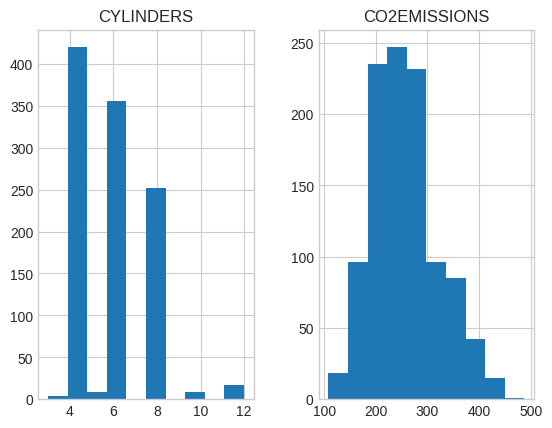

In [40]:
'''
Visualize features
Consider the histograms for each of these features.
'''
viz = cdf[['CYLINDERS','CO2EMISSIONS']]
viz.hist()
plt.show()

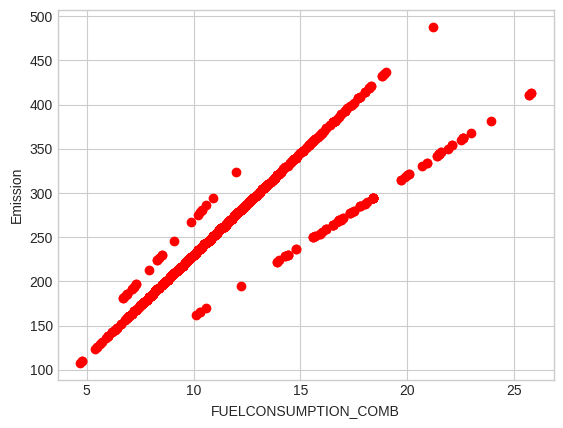

In [41]:
'''s you can see, most engines have 4, 6, or 8 cylinders, and engine sizes between 2 and 4 liters.
As you might expect, combined fuel consumption and CO2 emission have very similar distributions.
Go ahead and display some scatter plots of these features against the CO2 emissions, to see how linear their relationships are.
'''
plt.scatter(cdf.FUELCONSUMPTION_COMB, cdf.CO2EMISSIONS,  color='red')
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")
plt.show()

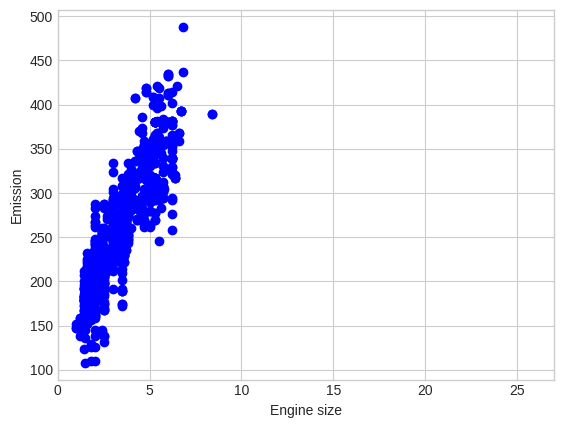

In [42]:
'''
This is an informative result. Three car groups each have a strong linear relationship between their combined fuel consumption and their CO2 emissions.
Their intercepts are similar, while they noticeably differ in their slopes.
'''
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS,  color='blue')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.xlim(0,27)
plt.show()